# Two-frame temperature extrapolation

The autoencoder and stochastic latent propagator were trained at 0.1 K and 1 K. Frame 0 and frame 1 are observed; frames 2–199 are autonomous predictions for unseen networks at 5, 10, 20 and 30 K. Temperature, source label and p-ratio are not model inputs.

Every result below uses the raw physical p-ratio at the stated frame. No line is fitted through the trajectory.


In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT=Path.cwd().resolve()
while not (ROOT/'notebooks').exists():
    if ROOT.parent==ROOT: raise RuntimeError('Run inside the repository')
    ROOT=ROOT.parent
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
from lss.plotting import apply_editorial_style, PAPER_COLORS, style_axes
RESULTS=ROOT/'notebooks/results/mixed_temperature_extrapolation_2frame'
RAW=RESULTS/'raw_pratio'
required=[RESULTS/'code_v2/protocol.json',RESULTS/'split_audit.json',RAW/'metadata.json',
          RAW/'per_step_network.csv',RAW/'final_network.csv',RAW/'summary_by_step.csv']
missing=[str(path) for path in required if not path.exists()]
if missing: raise FileNotFoundError('Missing frozen raw-p-ratio evaluation:\n'+'\n'.join(missing))
protocol=json.loads((RESULTS/'code_v2/protocol.json').read_text())
split_audit=json.loads((RESULTS/'split_audit.json').read_text())
metadata=json.loads((RAW/'metadata.json').read_text())
per_step=pd.read_csv(RAW/'per_step_network.csv')
final=pd.read_csv(RAW/'final_network.csv')
summary=pd.read_csv(RAW/'summary_by_step.csv',dtype={'temperature_K':str})
assert metadata['status']=='complete' and metadata['final_test_used'] is False
assert len(final)==162 and final.groupby('source').size().eq(81).all()
assert len(per_step)==162*200
apply_editorial_style('light')
SOURCES=['node_mixed','stiffness_mixed']
LABELS={'node_mixed':'node optimized','stiffness_mixed':'stiffness optimized'}
TEMPERATURES=[5.,10.,20.,30.]
TEMP_COLORS={5.0:'#3b4cc0',10.0:'#6f92f3',20.0:'#e7745b',30.0:'#b40426'}
print('Loaded raw frame-wise p-ratios for 162 unseen high-temperature trajectories.')


Loaded raw frame-wise p-ratios for 162 unseen high-temperature trajectories.


## Temperature split


In [2]:
split_rows=[]
for source,parts in split_audit.items():
    for split,counts in parts.items():
        for temperature,count in counts.items():
            split_rows.append({'source':LABELS[source],'split':split,'temperature (K)':float(temperature),'networks':count})
split_table=pd.DataFrame(split_rows)
display(split_table.sort_values(['split','source','temperature (K)']))


,source,split,temperature (K),networks
3,node optimized,evaluation,5.0,25
0,node optimized,evaluation,10.0,17
1,node optimized,evaluation,20.0,19
2,node optimized,evaluation,30.0,20
11,stiffness optimized,evaluation,5.0,25
8,stiffness optimized,evaluation,10.0,17
9,stiffness optimized,evaluation,20.0,19
10,stiffness optimized,evaluation,30.0,20
4,node optimized,train,0.1,17
5,node optimized,train,1.0,12


## Final p-ratio

Each point is the raw frame-199 p-ratio of one unseen network. The prediction comes from the mean decoded positions across eight autonomous rollouts. Colour is temperature; the dashed line is perfect agreement.


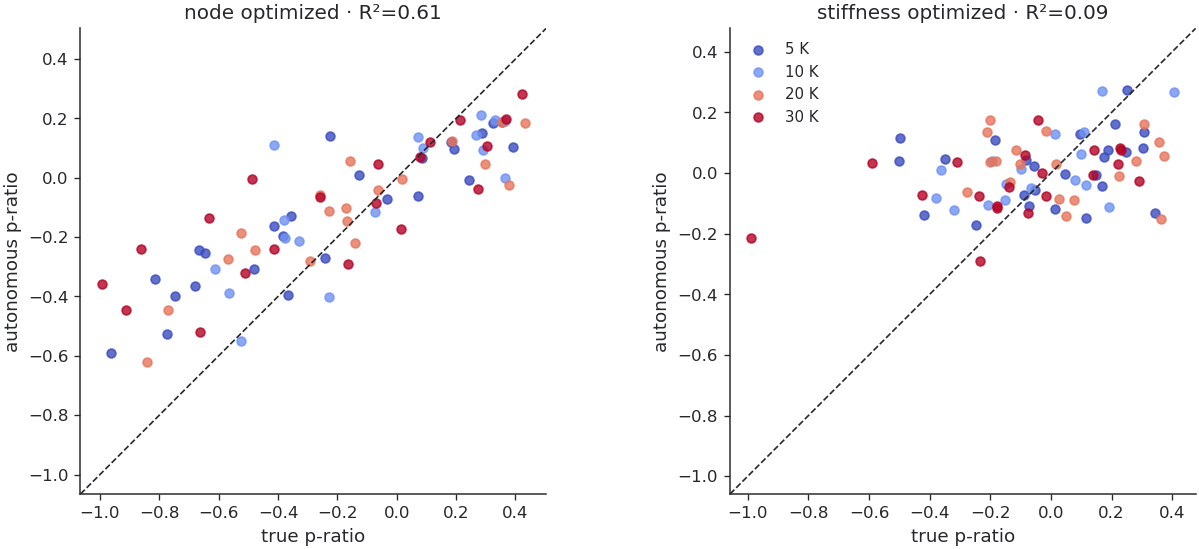

,source,temperature,p-ratio R²,MAE,valid/total
0,node optimized,all high-T,0.612,0.20,81/81
1,stiffness optimized,all high-T,0.089,0.19,81/81


In [3]:
fig,axes=plt.subplots(1,2,figsize=(10.8,4.6),constrained_layout=True)
final_rows=[]
for ax,source in zip(axes,SOURCES):
    values=final.query('source==@source')
    score=summary.query("source==@source and temperature_K=='all_high_T' and frame==199").iloc[0]
    low=min(values.true_p_ratio.min(),values.ensemble_mean_position_p_ratio.min())
    high=max(values.true_p_ratio.max(),values.ensemble_mean_position_p_ratio.max())
    pad=.05*max(high-low,1e-6); limits=(low-pad,high+pad)
    for temperature in TEMPERATURES:
        group=values.query('temperature_K==@temperature')
        ax.scatter(group.true_p_ratio,group.ensemble_mean_position_p_ratio,s=28,alpha=.8,
                   color=TEMP_COLORS[temperature],label=f'{temperature:g} K')
    ax.plot(limits,limits,'--',color=PAPER_COLORS['ink'],lw=1)
    ax.set(title=f"{LABELS[source]} · R²={score.p_ratio_r2:.2f}",xlim=limits,ylim=limits,aspect='equal')
    style_axes(ax,xlabel='true p-ratio',ylabel='autonomous p-ratio',legend=ax is axes[1])
    final_rows.append({'source':LABELS[source],'temperature':'all high-T','p-ratio R²':score.p_ratio_r2,
                       'MAE':score.p_ratio_mae,'valid/total':f'{int(score.valid)}/{int(score.total)}'})
plt.show()
display(pd.DataFrame(final_rows).round(3))


## Accuracy through the rollout

R² is recomputed across held-out networks at every frame. Each colour is one unseen temperature.


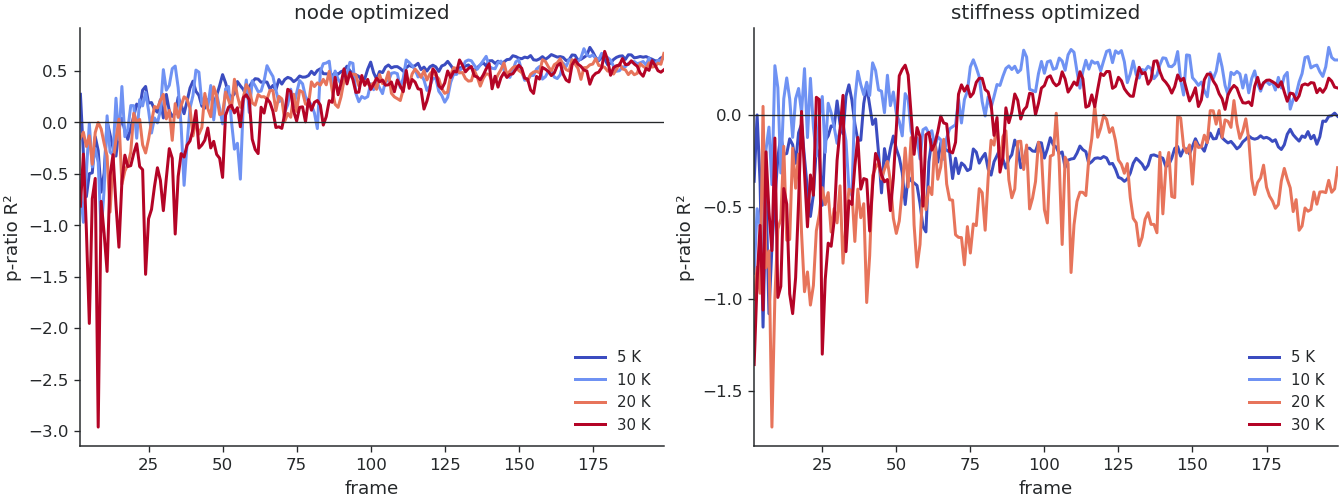

,source,temperature (K),p-ratio R²,MAE,valid,total
199,node optimized,5.0,0.637,0.212,25,25
399,node optimized,10.0,0.628,0.172,17,17
599,node optimized,20.0,0.670,0.174,19,19
799,node optimized,30.0,0.511,0.235,20,20
999,stiffness optimized,5.0,-0.008,0.186,25,25
1199,stiffness optimized,10.0,0.297,0.146,17,17
1399,stiffness optimized,20.0,-0.288,0.220,19,19
1599,stiffness optimized,30.0,0.145,0.203,20,20


In [4]:
fig,axes=plt.subplots(1,2,figsize=(11.2,4.2),constrained_layout=True)
for ax,source in zip(axes,SOURCES):
    for temperature in TEMPERATURES:
        temperature_key=f'{temperature:.1f}'
        values=(summary.query("source==@source and temperature_K==@temperature_key")
                .sort_values('frame').query('frame>=2'))
        ax.plot(values.frame,values.p_ratio_r2,color=TEMP_COLORS[temperature],lw=1.8,label=f'{temperature:g} K')
    ax.axhline(0,color=PAPER_COLORS['ink'],lw=.8)
    ax.set(title=LABELS[source],xlim=(2,199))
    style_axes(ax,xlabel='frame',ylabel='p-ratio R²',legend=True)
plt.show()

endpoint=summary.query("frame==199 and temperature_K!='all_high_T'").copy()
endpoint['temperature_K']=pd.to_numeric(endpoint.temperature_K)
display(endpoint[['source','temperature_K','p_ratio_r2','p_ratio_mae','valid','total']]
        .assign(source=lambda x:x.source.map(LABELS))
        .rename(columns={'temperature_K':'temperature (K)','p_ratio_r2':'p-ratio R²','p_ratio_mae':'MAE'})
        .sort_values(['source','temperature (K)']).round(3))


## Per-frame p-ratio

For each temperature, the displayed network is the one nearest that temperature group's median true frame-199 p-ratio. Solid is ground truth and dashed is the autonomous prediction.


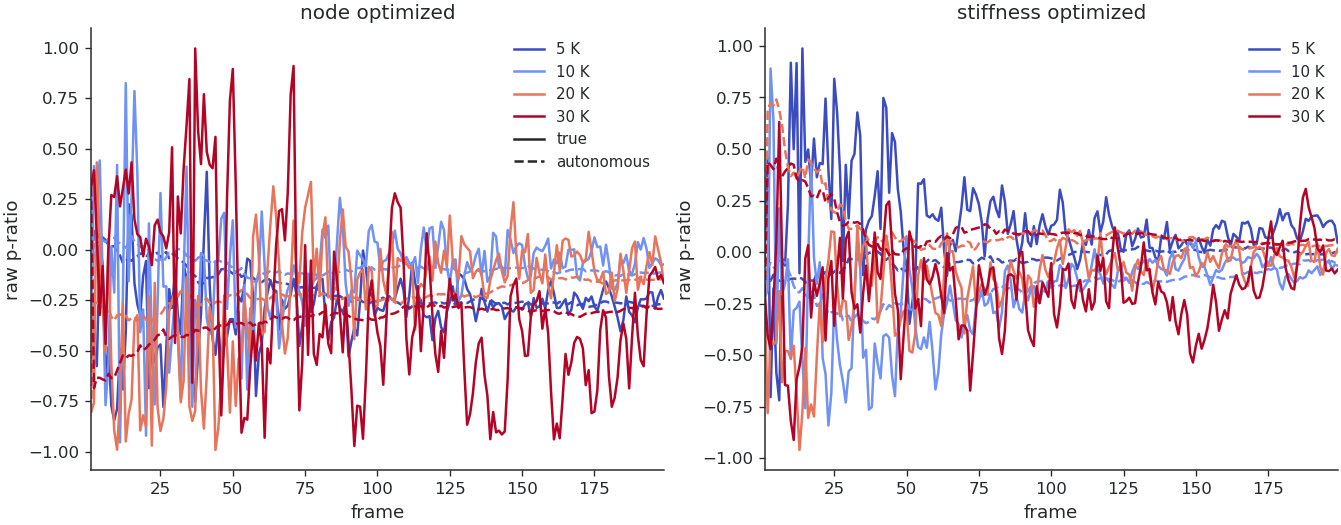

,source,trajectory_id,temperature (K)
53,node optimized,82,5.0
36,node optimized,59,10.0
55,node optimized,84,20.0
14,node optimized,27,30.0
134,stiffness optimized,82,5.0
160,stiffness optimized,118,10.0
107,stiffness optimized,44,20.0
147,stiffness optimized,99,30.0


In [5]:
selected=[]
for source in SOURCES:
    for temperature in TEMPERATURES:
        group=final.query('source==@source and temperature_K==@temperature')
        target=group.true_p_ratio.median()
        selected.append(group.loc[(group.true_p_ratio-target).abs().idxmin(),['source','trajectory_id','temperature_K']])
selected=pd.DataFrame(selected)

fig,axes=plt.subplots(1,2,figsize=(11.2,4.4),constrained_layout=True)
for ax,source in zip(axes,SOURCES):
    for row in selected.query('source==@source').itertuples():
        trajectory_id=int(row.trajectory_id)
        values=per_step.query('source==@source and trajectory_id==@trajectory_id').sort_values('frame')
        color=TEMP_COLORS[row.temperature_K]
        ax.plot(values.frame,values.true_p_ratio,color=color,lw=1.5,label=f'{row.temperature_K:g} K')
        ax.plot(values.frame,values.ensemble_mean_position_p_ratio,color=color,lw=1.5,ls='--')
    ax.set(title=LABELS[source],xlim=(1,199))
    style_axes(ax,xlabel='frame',ylabel='raw p-ratio',legend=True)
axes[0].plot([],[],color=PAPER_COLORS['ink'],lw=1.5,label='true')
axes[0].plot([],[],color=PAPER_COLORS['ink'],lw=1.5,ls='--',label='autonomous')
axes[0].legend()
plt.show()
display(selected.assign(source=lambda x:x.source.map(LABELS)).rename(columns={'temperature_K':'temperature (K)'}))


## Result

These panels test the p-ratio produced by decoded autonomous positions directly. The frame-wise curves show when the prediction becomes mechanically informative, while the frame-199 scatter gives the final response without smoothing it with a trajectory fit.
